# 🌋 Asistente turístico de Tenerife con LLM

**Máster en Inteligencia Artificial, Cloud Computing y DevOps · Large Language Models · Entrega final**<br>
Autor: Antonio

Este notebook es el producto principal de la práctica. Construye y evalúa un asistente conversacional que:

1. **Responde con RAG** sobre la guía turística facilitada (`data/TENERIFE.pdf`) y **cita las fuentes** (lugar y página).
2. **Mantiene el contexto** en conversaciones multiturno, con una memoria acotada por tokens.
3. **Llama a funciones externas**: `get_weather(fecha, zona)` con previsión real de Open-Meteo, validación con Pydantic, reintentos y log; y `buscar_en_guia` para que el modelo haga búsquedas adicionales (agente con varias herramientas).

Extras (bonus): interfaz web en Streamlit, respuestas en *streaming*, entrada de fotos (multimodal) y observabilidad con logs estructurados.

> Toda la lógica está en el paquete `src/tenerife_assistant/` (código modular, con docstrings y tests). El notebook la usa, la explica y la evalúa.

**Índice**

0. Configuración y conexión con el LLM
1. Carga de la guía
2. *Chunking*
3. Embeddings e índice vectorial (FAISS)
4. Evaluación de la recuperación (sin LLM)
5. El asistente: prompt, memoria y herramientas
6. Conversación de ejemplo multiturno
7. *Function calling*: `get_weather`
8. *Streaming* y multimodalidad
9. Control de la longitud del contexto
10. Evaluación extremo a extremo
11. Observabilidad
12. Casos límite y análisis crítico
13. Conclusiones

### Arquitectura

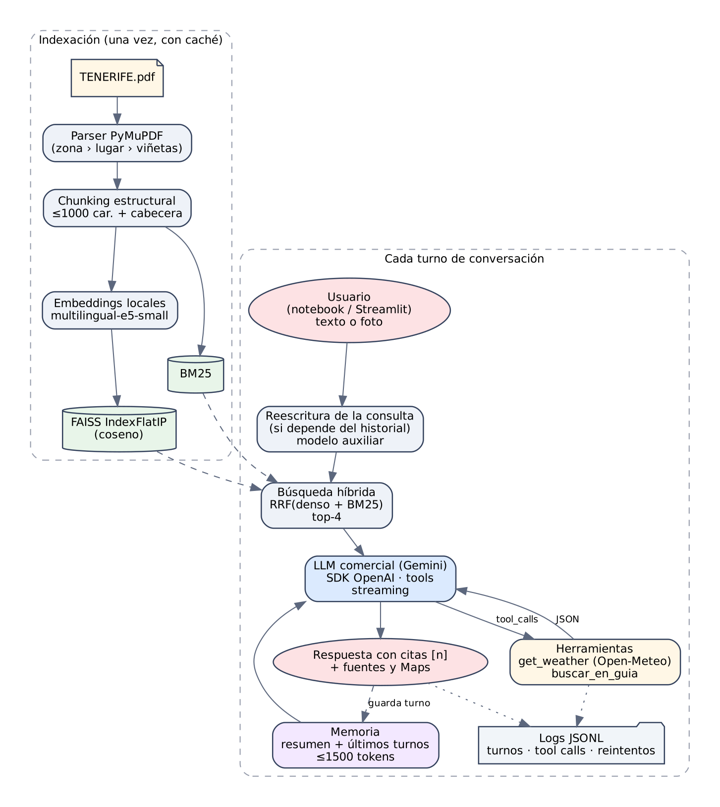

Decisión clave: uso el **SDK oficial de OpenAI** también para Gemini, gracias al endpoint compatible de Google. Así el mismo código funciona con los dos proveedores cambiando `LLM_PROVIDER` en el `.env`.

## 0. Configuración y conexión con el LLM

La API key se lee de un fichero `.env` (que está en `.gitignore`) mediante `python-dotenv`. Nunca aparece en el código ni en las salidas: `Settings.describe()` la enmascara.

In [1]:
import json
import logging
import os
import sys
import time
import warnings
from pathlib import Path

# Raíz del repositorio: la primera carpeta (hacia arriba) que contiene src/tenerife_assistant
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "tenerife_assistant").exists())
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))  # por si el paquete no está instalado con `pip install -e .`

for var, value in {"TOKENIZERS_PARALLELISM": "false", "HF_HUB_DISABLE_PROGRESS_BARS": "1",
                   "HF_HUB_VERBOSITY": "error", "TRANSFORMERS_VERBOSITY": "error"}.items():
    os.environ.setdefault(var, value)
warnings.filterwarnings("ignore")
logging.basicConfig(level=logging.WARNING, format="%(levelname)s %(name)s: %(message)s")
logging.getLogger("tenerife_assistant").setLevel(logging.INFO)
for noisy in ("httpx", "httpx2", "sentence_transformers", "faiss.loader", "huggingface_hub"):
    logging.getLogger(noisy).setLevel(logging.ERROR)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

from tenerife_assistant.config import ModelParams, Settings

pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 160)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "font.size": 10})

settings = Settings.from_env()
config = settings.describe()
print(f"Proveedor: {config['provider']} · base_url: {config['base_url']} · API key: {config['api_key']}")

Proveedor: gemini · base_url: https://generativelanguage.googleapis.com/v1beta/openai/ · API key: ******** (definida)


**Parámetros del modelo.** Están todos expuestos en `ModelParams` y se pueden cambiar desde el `.env` (o desde la barra lateral de la app web):

- `temperature`: aleatoriedad del muestreo. Para Gemini 3 Google recomienda **mantener 1.0**, porque bajarla puede provocar bucles o peor rendimiento. La fidelidad a la guía la controlo con el *prompt* y las citas, no bajando la temperatura.
- `top_p`: *nucleus sampling*; se descarta la cola de tokens poco probables (0.95).
- `max_tokens`: límite de salida. **En Gemini incluye los tokens de razonamiento**, por eso dejo margen (2048).
- `reasoning_effort`: cuánto "piensa" el modelo antes de responder.

Uso un **modelo principal** para el chat y un **modelo auxiliar** más rápido para tareas internas (reescribir consultas, resumir la memoria, describir fotos). Si el principal agota su **cuota diaria gratuita**, el cliente cambia solo a un **modelo de reserva**.

In [2]:
params_table = pd.DataFrame(
    [
        {"rol": "chat (principal)", **config["chat"]},
        {"rol": "auxiliar", **config["utility"]},
    ]
).set_index("rol")
display(params_table.fillna("—"))
print("Modelos de reserva:", ", ".join(settings.fallback_models) or "(ninguno)")
print("RAG:", {k: config[k] for k in ("embedding_model", "chunk_strategy", "chunk_max_chars", "retrieval_method", "top_k")})
print("Memoria:", {k: config[k] for k in ("memory_max_tokens", "memory_keep_turns", "rewrite_queries")})

,model,temperature,top_p,max_tokens,reasoning_effort
rol,,,,,
chat (principal),gemini-3.5-flash-lite,1.0,0.95,2048,low
auxiliar,gemini-3.1-flash-lite,1.0,0.95,512,—


Modelos de reserva: gemini-3.1-flash-lite, gemma-4-26b-a4b-it
RAG: {'embedding_model': 'intfloat/multilingual-e5-small', 'chunk_strategy': 'structural', 'chunk_max_chars': 1000, 'retrieval_method': 'hybrid', 'top_k': 4}
Memoria: {'memory_max_tokens': 1500, 'memory_keep_turns': 2, 'rewrite_queries': 'auto'}


In [3]:
from tenerife_assistant.llm import LLMClient

llm = LLMClient(settings)
t0 = time.perf_counter()
reply = llm.complete(
    [{"role": "user", "content": "Responde solo con: 'Conexión OK' y el nombre del pico más alto de España."}],
    purpose="smoke-test",
)
print(f"{reply.choices[0].message.content!r}  ({time.perf_counter() - t0:.2f} s, {reply.usage.total_tokens} tokens)")

'Conexión OK - El Teide'  (1.22 s, 196 tokens)


## 1. Carga de la guía

La guía es un Word exportado a PDF con una estructura muy clara, que leo con **PyMuPDF** usando la posición y la tipografía de cada línea:

| Elemento | Cómo se reconoce | Ejemplo |
|---|---|---|
| Zona | negrita, mayúsculas, pegada al margen | `ZONA NORTE` |
| Lugar | viñeta `•` | `• La Orotava` |
| Punto de interés | viñeta `o` (sangría 127 pt) | `o Playa del Bollullo` |
| Restaurante | viñeta `▪` | `▪ Arepera La Carajita` |

Al exportar se **perdieron los hipervínculos**, pero quedaron las etiquetas (`[vídeo - ubicación]`, `(ubicación)`, `[web]`…). Las elimino porque solo meten ruido en los embeddings.

In [4]:
from tenerife_assistant.ingest import clean_text, load_guide

sections = load_guide(settings.pdf_path)
overview = pd.DataFrame(
    [{"zona": s.zone, "lugar": s.title, "páginas": f"{s.pages[0]}-{s.pages[-1]}", "bloques": len(s.blocks),
      "caracteres": len(s.text)} for s in sections]
)
print(f"{len(sections)} lugares · {overview['caracteres'].sum():,} caracteres de texto útil (el PDF tiene 25 páginas y 37 fotos)")
display(overview)

13 lugares · 14,765 caracteres de texto útil (el PDF tiene 25 páginas y 37 fotos)


,zona,lugar,páginas,bloques,caracteres
0,Zona Norte,Santa Cruz de Tenerife,1-3,13,752
1,Zona Norte,San Cristóbal de La Laguna,3-4,6,695
2,Zona Norte,Parque rural de Anaga,5-8,4,1243
3,Zona Norte,La Orotava,8-11,9,1566
4,Zona Norte,Puerto de La Cruz,11-11,1,1120
5,Zona Norte,"Isla Baja (Icod de los Vinos, Garachico y Punta de Teno)",12-14,5,2121
6,Zona Norte,El Teide,15-16,1,1253
7,Zona Sur,Costa Adeje,16-21,5,2031
8,Zona Sur,Los Gigantes,21-21,1,424
9,Zona Sur,Masca,22-22,1,575


In [5]:
ejemplo = "Plaza de España [vídeo - ubicación] · subir la Calle Castillo dirección Plaza Weyler - ubicación –; aparcar (ubicación)."
print("Antes  :", ejemplo)
print("Después:", clean_text(ejemplo))

Antes  : Plaza de España [vídeo - ubicación] · subir la Calle Castillo dirección Plaza Weyler - ubicación –; aparcar (ubicación).
Después: Plaza de España · subir la Calle Castillo dirección Plaza Weyler; aparcar.


## 2. *Chunking*

He implementado dos estrategias para compararlas con datos (sección 4):

- **Estructural** (la elegida): cada fragmento pertenece a **un único lugar**, agrupa viñetas completas hasta ~1000 caracteres y solo corta por frases si un párrafo no cabe. Además, se vectoriza con su **cabecera jerárquica** (`Zona Norte › La Orotava`), de modo que un fragmento sobre "la Calle de la Carrera" sigue sabiendo que es de La Orotava aunque el texto no lo repita.
- **Tamaño fijo con solapamiento** (línea base): ventanas de N caracteres con solape, cortando en espacios.

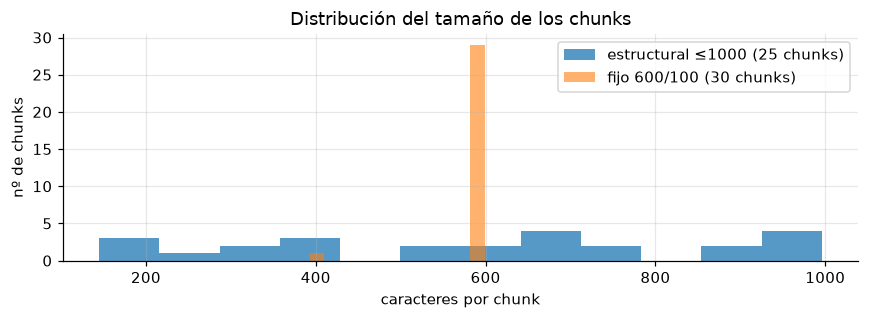

Ejemplo — id=s04-1 · cita: Guía de Tenerife · Zona Norte › La Orotava (págs. 8-9)

Zona Norte › La Orotava
Este es el pueblo más bonito y maravilloso del mundo (no es porque yo sea de allí). De La Orotava os recomendaría aparcar en esta explanada e ir caminando hacia la conocida como Plaza de Anita (no es su nombre oficial, pero todo el mundo la conoce por este nombre). Ahí podréis ver el Liceo de Taoro y los Jardínes Victoria. Una vez visto esto, recorrer la Calle de la Carrera, donde se puede ver el ayuntamiento de La Orotava, la Iglesia de La Concepción, la casa Lercaro y la Casa de los Balcones. Al final de esta calle también está el molino de Chano, donde podréis comprar gofio si os apetece. Curiosidades:
El casco histórico de La Orotava es Conjunto Histórico Artístic …


In [6]:
from tenerife_assistant.ingest import build_chunks

chunks = build_chunks(sections, settings.chunk_strategy, max_chars=settings.chunk_max_chars)
fixed = build_chunks(sections, "fixed", size=600, overlap=100)

fig, ax = plt.subplots(figsize=(8, 3))
ax.hist([len(c.text) for c in chunks], bins=12, alpha=0.75, label=f"estructural ≤1000 ({len(chunks)} chunks)")
ax.hist([len(c.text) for c in fixed], bins=12, alpha=0.6, label=f"fijo 600/100 ({len(fixed)} chunks)")
ax.set_xlabel("caracteres por chunk"); ax.set_ylabel("nº de chunks"); ax.legend(); ax.set_title("Distribución del tamaño de los chunks")
plt.tight_layout(); plt.show()

ejemplo = next(c for c in chunks if c.section == "La Orotava")
print(f"Ejemplo — id={ejemplo.chunk_id} · cita: {ejemplo.citation}\n")
print(ejemplo.embedding_text[:700], "…")

El chunking fijo corta a mitad de una idea y mezcla lugares (un fragmento puede empezar en el Teide y acabar en Costa Adeje), lo que confunde tanto la búsqueda como las citas.

In [7]:
# ¿Cuántos chunks de tamaño fijo cruzan la frontera entre dos lugares de la guía?
spans, pos = [], 0
for s in sections:
    spans.append((pos, pos + len(s.text) + 1, s.title)); pos += len(s.text) + 1
full = "\n".join(s.text for s in sections)
cruzan = 0
for c in fixed:
    start = full.find(c.text[:60].split("\n")[0][:40])
    lugares = {t for a, b, t in spans if start != -1 and a < start + len(c.text) and b > start}
    cruzan += len(lugares) > 1
print(f"Chunks de tamaño fijo que mezclan texto de dos lugares: {cruzan} de {len(fixed)}")
print(f"Chunks estructurales que mezclan lugares: 0 de {len(chunks)} (por construcción)")

Chunks de tamaño fijo que mezclan texto de dos lugares: 11 de 30
Chunks estructurales que mezclan lugares: 0 de 25 (por construcción)


## 3. Embeddings e índice vectorial (FAISS)

- **Embeddings locales** con `intfloat/multilingual-e5-small` (118 M parámetros, 384 dimensiones, multilingüe). Son gratuitos, no tienen límite de peticiones y hacen la evaluación de la recuperación reproducible sin API. Los modelos E5 necesitan los prefijos `query:` / `passage:`, que añado automáticamente.
- **Vector store FAISS `IndexFlatIP`** sobre vectores normalizados, es decir, similitud coseno exacta. Con ~25 vectores la búsqueda exacta tarda microsegundos; un índice aproximado (IVF, HNSW) solo compensa con cientos de miles.
- **Índice en disco con caché**: se guarda en `index/` junto a un manifiesto (hash del PDF, modelo, estrategia y versión del *chunker*). Si nada cambia, se carga sin recalcular embeddings.
- **Búsqueda híbrida**: combino FAISS con **BM25** mediante *Reciprocal Rank Fusion*. BM25 ayuda con nombres propios que el modelo denso no conoce ("Rugantino", "Guachinche El Cubano").

In [8]:
from tenerife_assistant.assistant import build_default_retriever

t0 = time.perf_counter()
retriever = build_default_retriever(settings)
print(f"Retriever listo en {time.perf_counter() - t0:.1f} s · {len(retriever.chunks)} chunks · "
      f"dimensión {retriever.dense.index.d} · vectores en FAISS: {retriever.dense.index.ntotal}")
print(json.dumps(json.loads((settings.index_dir / "manifest.json").read_text()), indent=2, ensure_ascii=False))

INFO tenerife_assistant.retrieval: Índice construido en 1.75 s


Retriever listo en 11.7 s · 25 chunks · dimensión 384 · vectores en FAISS: 25
{
  "pdf_sha256": "581bed07ac33b073e950f60cf8a4ec0fe2c781b4359dea14d15a4a73a64b16dd",
  "chunker_version": "1.2",
  "chunk_strategy": "structural",
  "chunk_max_chars": 1000,
  "embedding_model": "intfloat/multilingual-e5-small",
  "n_chunks": 25,
  "built_at": "2026-10-11 02:58:14",
  "build_seconds": 1.7510967239995807
}


In [9]:
from tenerife_assistant.retrieval import Retriever

query = "playa de arena negra para ver el atardecer"
rows = []
for method in ("dense", "bm25", "hybrid"):
    r = Retriever(retriever.dense, retriever.bm25, method=method)
    for res in r.search(query, k=3):
        rows.append({"método": method, "rank": res.rank, "score": round(res.score, 3),
                     "lugar": res.chunk.header, "fragmento": res.chunk.text[:90] + "…"})
print(f"Consulta: «{query}»")
display(pd.DataFrame(rows))

Consulta: «playa de arena negra para ver el atardecer»


,método,rank,score,lugar,fragmento
0,dense,1,0.883,Zona Norte › Parque rural de Anaga,"Playa de Benijo Playa de arena negra, si el día está despejado, de los atardeceres más esp…"
1,dense,2,0.835,Zona Norte › El Teide,"Y, si queréis más info sobre el Teide, podéis ir al Centro de Visitantes de El Portillo qu…"
2,dense,3,0.829,Otras Vainas › Sitios para comer,Zona Norte\nTerrazas del Sauzal (zona de El Sauzal – entre La Laguna y La Orotava. Tienen u…
3,bm25,1,6.797,Zona Sur › Costa Adeje,Costa Adeje es actualmente la zona turística por excelencia de Tenerife. Es donde se conce…
4,bm25,2,6.497,Zona Norte › Parque rural de Anaga,"Playa de Benijo Playa de arena negra, si el día está despejado, de los atardeceres más esp…"
5,bm25,3,2.286,Zona Norte › Parque rural de Anaga,"Es un espacio natural protegido, declarado Reserva de la Biosfera y que cuenta con la mayo…"
6,hybrid,1,0.033,Zona Norte › Parque rural de Anaga,"Playa de Benijo Playa de arena negra, si el día está despejado, de los atardeceres más esp…"
7,hybrid,2,0.032,Zona Sur › Costa Adeje,Costa Adeje es actualmente la zona turística por excelencia de Tenerife. Es donde se conce…
8,hybrid,3,0.031,Zona Sur › Los Cristianos,De la zona de Los Cristianos que me venga a la mente os recomendaría la Playa de Los Crist…


## 4. Evaluación de la recuperación (sin LLM)

Para elegir chunking, modelo y método con datos he creado un conjunto de **40 preguntas** (`eval/retrieval_questions.json`), muchas **parafraseadas** a propósito ("cetáceos" en vez de "delfines y ballenas", "comida venezolana" en vez de "arepas"). Cada pregunta lleva una **evidencia literal** de la guía: un resultado es correcto si el chunk recuperado la contiene. Así la métrica no depende de cómo esté troceado el documento.

Métricas: **Hit@k** (¿aparece la evidencia en los k primeros?) y **MRR** (media de 1/posición del primer acierto).

In [10]:
from tenerife_assistant.evaluation import load_json, retrieval_grid

rq = load_json(ROOT / "eval" / "retrieval_questions.json")
questions, ood_questions = rq["in_domain"], rq["out_of_domain"]
print(f"{len(questions)} preguntas dentro de dominio ({sum(q['tipo']=='parafrasis' for q in questions)} parafraseadas) · "
      f"{len(ood_questions)} fuera de dominio")

configs = [("structural", {"max_chars": m}) for m in (500, 1000, 1400)] + \
          [("fixed", {"size": s, "overlap": o}) for s, o in ((300, 50), (600, 100), (1000, 150))]
grid = retrieval_grid(sections, questions, retriever.dense.embedder, configs)
grid.to_csv(ROOT / "eval" / "results" / "retrieval_grid.csv", index=False)
display(grid.sort_values("MRR", ascending=False).reset_index(drop=True))

40 preguntas dentro de dominio (31 parafraseadas) · 10 fuera de dominio


,chunking,metodo,n_chunks,chars_medio,indexado_s,hit@1,hit@3,hit@5,MRR,latencia_ms
0,structural-1400,dense,18,820,1.74,0.850,0.950,0.950,0.896,18.31
1,structural-1000,hybrid,25,590,1.77,0.800,0.925,0.950,0.860,17.66
2,structural-1400,hybrid,18,820,1.74,0.825,0.900,0.900,0.854,19.11
3,structural-1000,dense,25,590,1.77,0.750,0.900,0.975,0.834,18.65
4,structural-500,hybrid,42,351,1.29,0.725,0.900,0.975,0.826,19.37
5,structural-500,dense,42,351,1.29,0.750,0.900,0.925,0.826,18.27
6,fixed-1000-150,dense,18,962,1.21,0.725,0.900,0.975,0.815,19.37
7,fixed-1000-150,hybrid,18,962,1.21,0.750,0.900,0.900,0.808,21.33
8,structural-1400,bm25,18,820,1.74,0.725,0.875,0.875,0.796,0.08
9,structural-1000,bm25,25,590,1.77,0.675,0.875,0.900,0.769,0.07


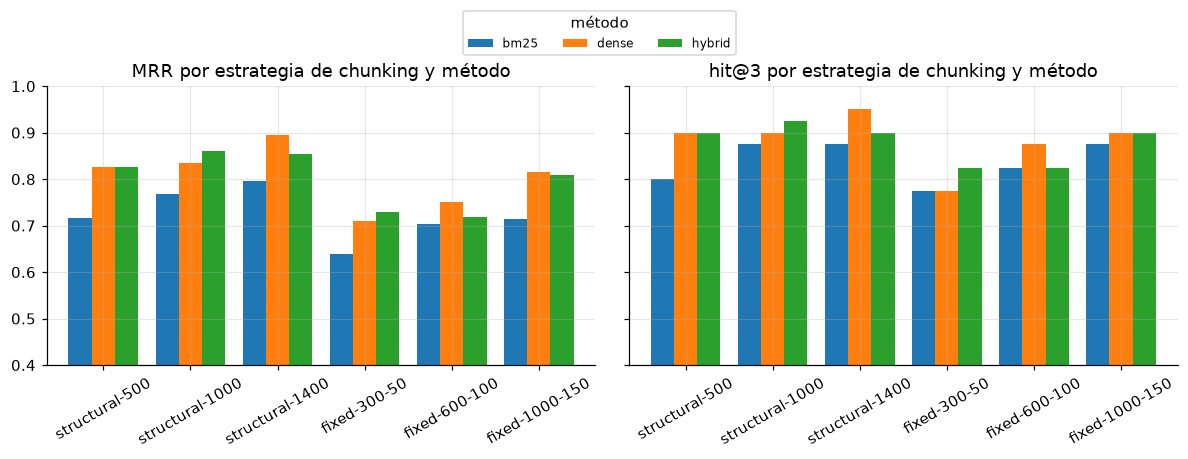

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
order = [f"{s}-{'-'.join(map(str, p.values()))}" for s, p in configs]
for ax, metric in zip(axes, ("MRR", "hit@3")):
    pivot = grid.pivot(index="chunking", columns="metodo", values=metric).loc[order]
    pivot.plot.bar(ax=ax, rot=30, width=0.8, legend=False)
    ax.set_title(f"{metric} por estrategia de chunking y método"); ax.set_xlabel(""); ax.set_ylim(0.4, 1.0)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, title="método", ncol=3, loc="upper center", bbox_to_anchor=(0.5, 1.1), fontsize=8)
plt.tight_layout()
plt.savefig(ROOT / "docs" / "img" / "retrieval_grid.png", dpi=150, bbox_inches="tight"); plt.show()

**Comparativa de modelos de embeddings** con el chunking elegido. Incluyo un modelo por API (`gemini-embedding-001`) para comparar local frente a nube. Si se agota su cuota gratuita (100 peticiones por minuto), la celda lo indica y sigue.

In [12]:
from tenerife_assistant.retrieval import APIEmbedder, SentenceTransformerEmbedder

cfg = [("structural", {"max_chars": settings.chunk_max_chars})]
model_rows = []
candidates = {
    "multilingual-e5-small (local)": lambda: retriever.dense.embedder,
    "multilingual-e5-base (local)": lambda: SentenceTransformerEmbedder("intfloat/multilingual-e5-base"),
    "paraphrase-multilingual-MiniLM-L12-v2 (local)": lambda: SentenceTransformerEmbedder(
        "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2"),
}
if settings.provider == "gemini":
    candidates["gemini-embedding-001 (API)"] = lambda: APIEmbedder(llm.client, "gemini-embedding-001")

for name, factory in candidates.items():
    try:
        t0 = time.perf_counter()
        emb = factory()
        res = retrieval_grid(sections, questions, emb, cfg, methods=("dense",))
        res.insert(0, "modelo", name)
        res["tiempo_total_s"] = round(time.perf_counter() - t0, 1)
        model_rows.append(res)
    except Exception as exc:  # p. ej. cuota de la API agotada
        print(f"⚠️ {name}: no evaluado ({type(exc).__name__}: {str(exc)[:120]})")

models_df = pd.concat(model_rows, ignore_index=True)
models_df.to_csv(ROOT / "eval" / "results" / "embedding_models.csv", index=False)
display(models_df[["modelo", "hit@1", "hit@3", "hit@5", "MRR", "latencia_ms", "tiempo_total_s"]])

,modelo,hit@1,hit@3,hit@5,MRR,latencia_ms,tiempo_total_s
0,multilingual-e5-small (local),0.750,0.900,0.975,0.834,16.29,2.7
1,multilingual-e5-base (local),0.725,0.900,0.950,0.815,47.08,11.5
2,paraphrase-multilingual-MiniLM-L12-v2 (local),0.400,0.525,0.650,0.486,16.20,4.7
3,gemini-embedding-001 (API),0.900,1.000,1.000,0.938,177.92,7.9


In [13]:
from tenerife_assistant.evaluation import evaluate_retrieval

detail = evaluate_retrieval(retriever, questions, k_values=(1, 3, 4, 5))
print("Configuración final (estructural-1000 + híbrida, top-4):",
      {k: round(float(detail[k].mean()), 3) for k in ("hit@1", "hit@3", "hit@4")}, "MRR:", round(float(detail["rr"].mean()), 3))
print("\nPor tipo de pregunta:")
display(detail.groupby("tipo")[["hit@1", "hit@4", "rr"]].mean().round(3))
fallos = detail[detail["hit@4"] == 0][["id", "pregunta", "top1"]]
print(f"\nPreguntas sin la evidencia en el top-4 ({len(fallos)}):")
display(fallos)

Configuración final (estructural-1000 + híbrida, top-4): {'hit@1': 0.8, 'hit@3': 0.925, 'hit@4': 0.95} MRR: 0.86

Por tipo de pregunta:


,hit@1,hit@4,rr
tipo,,,
lexica,0.889,1.000,0.944
parafrasis,0.774,0.935,0.836



Preguntas sin la evidencia en el top-4 (2):


,id,pregunta,top1
29,r30,¿Dónde puedo hacer una excursión para ver cetáceos?,Zona Norte › Puerto de La Cruz
34,r35,¿Dónde como comida venezolana barata?,Otras Vainas › Sitios para comer


**¿Se pueden detectar las preguntas fuera de dominio con un umbral de similitud?** Comparo la similitud coseno del mejor chunk para las 40 preguntas de la guía y 10 preguntas que no tienen nada que ver ("capital de Francia", "receta de paella"…).

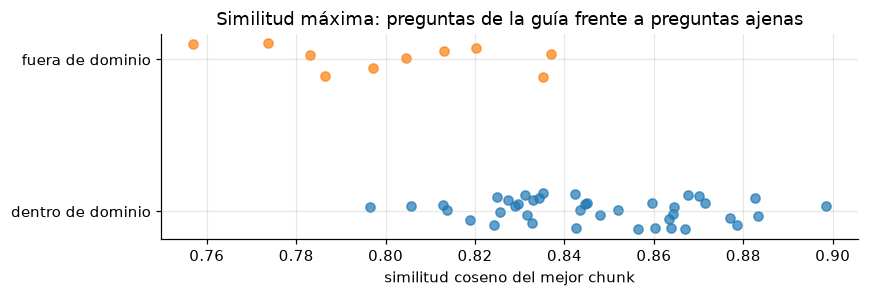

,min,mean,max
grupo,,,
dentro de dominio,0.796,0.846,0.899
fuera de dominio,0.757,0.801,0.837


In [14]:
from tenerife_assistant.evaluation import ood_scores

ood = ood_scores(Retriever(retriever.dense, None, method="dense"), questions, ood_questions)
fig, ax = plt.subplots(figsize=(8, 2.8))
for i, (grupo, sub) in enumerate(ood.groupby("grupo")):
    ax.scatter(sub["max_sim"], np.full(len(sub), i) + np.random.default_rng(0).uniform(-0.12, 0.12, len(sub)), alpha=0.7, label=grupo)
ax.set_yticks([0, 1], ["dentro de dominio", "fuera de dominio"]); ax.set_xlabel("similitud coseno del mejor chunk")
ax.set_title("Similitud máxima: preguntas de la guía frente a preguntas ajenas")
plt.tight_layout(); plt.savefig(ROOT / "docs" / "img" / "ood_similarity.png", dpi=150); plt.show()
display(ood.groupby("grupo")["max_sim"].describe()[["min", "mean", "max"]].round(3))

## 5. El asistente: *prompt*, memoria y herramientas

`TourismAssistant` orquesta cada turno:

1. **Reescritura de la consulta** (solo si la pregunta depende del historial, p. ej. "¿y dónde como por allí?"): el modelo auxiliar la convierte en una consulta autónoma ("dónde comer en La Orotava"). Una heurística decide si hace falta, para ahorrar una llamada en preguntas autónomas.
2. **Búsqueda híbrida** top-4 y construcción del contexto con **fuentes numeradas** `[1]…[4]`.
3. **Llamada al LLM** con el *system prompt*, la memoria y dos herramientas. Si el modelo pide herramientas, se ejecutan y se le devuelve el resultado (máximo 4 rondas).
4. **Validación de citas**: se detectan números `[n]` que no correspondan a ninguna fuente (citas inventadas).
5. **Memoria y log**: se guarda el turno y se registra todo en `logs/turns.jsonl`.

In [15]:
from tenerife_assistant.assistant import SYSTEM_PROMPT, create_assistant
from tenerife_assistant.tools import WeatherService

weather = WeatherService(mode=settings.weather_mode)
assistant = create_assistant(settings, retriever=retriever, llm=llm, weather=weather)
print(assistant._system_prompt())

Eres «Guía Tenerife», un asistente turístico que ayuda a planificar visitas a Tenerife a partir de una guía escrita por una persona local.

Hoy es domingo 2026-10-11. Próximos días: lunes 2026-10-12, martes 2026-10-13, miércoles 2026-10-14, jueves 2026-10-15, viernes 2026-10-16, sábado 2026-10-17, domingo 2026-10-18.

Normas:
1. Basa tus respuestas en el CONTEXTO DE LA GUÍA y en los resultados de las herramientas. No inventes horarios, precios, direcciones ni lugares. Si la guía no trata algo, dilo claramente («La guía no incluye información sobre…») y, como mucho, sugiere qué parte de la guía sí puede ayudar.
2. Cita cada dato que saques de la guía con el número de su fuente entre corchetes, p. ej. [1] o [2][3]. Usa solo números de fuentes del contexto de ESTE turno (la numeración cambia en cada pregunta) y solo si esa fuente contiene el dato; lo que venga de la conversación anterior no lleva cita.
3. Para el tiempo usa la herramienta get_weather (convierte «mañana», «el sábado»… a fe

In [16]:
print("Herramientas expuestas al modelo (JSON Schema generado con Pydantic):\n")
print(json.dumps(assistant.tools.schemas(), indent=2, ensure_ascii=False))

Herramientas expuestas al modelo (JSON Schema generado con Pydantic):

[
  {
    "type": "function",
    "function": {
      "name": "get_weather",
      "description": "Devuelve la previsión del tiempo en Tenerife para una fecha (de hoy a 15 días) y una zona: estado del cielo, temperaturas, probabilidad de lluvia, viento, índice UV y horas de amanecer y atardecer. Úsala siempre que el usuario pregunte por el tiempo o cuando la recomendación dependa de él (playas, atardeceres, subir al Teide).",
      "parameters": {
        "additionalProperties": false,
        "properties": {
          "fecha": {
            "description": "Fecha de la previsión en formato YYYY-MM-DD. Convierte expresiones como 'mañana' o 'el sábado' a una fecha concreta usando la fecha de hoy.",
            "type": "string"
          },
          "zona": {
            "description": "Zona de Tenerife. Usa la más cercana al lugar del que se habla: p. ej. Benijo o Pico del Inglés -> anaga; Garachico o Icod -> isla_ba

In [17]:
def mostrar(r, titulo=None, pregunta=None):
    # Muestra una respuesta del asistente con sus citas, herramientas y métricas.
    partes = [f"#### {titulo}"] if titulo else []
    partes.append(r.text)
    citadas = r.cited_sources
    if citadas:
        partes.append("**Fuentes:** " + " · ".join(
            f"[{s['n']}] {s['cita'].replace('Guía de Tenerife · ', '')}" for s in citadas))
    if r.tool_calls:
        partes.append("**Herramientas:** " + " · ".join(
            f"`{t['name']}({json.dumps(t['arguments'], ensure_ascii=False)})` {'✅' if t['ok'] else '⚠️ ' + str(t['result'].get('tipo_error'))}"
            for t in r.tool_calls))
    reescrita = pregunta is not None and r.search_query.strip() != pregunta.strip()
    extra = f" · consulta reescrita: «{r.search_query}»" if reescrita else ""
    partes.append(f"<sub>⏱️ {r.latency_s:.1f} s · {r.llm_calls} llamadas al LLM · "
                  f"{r.usage.get('total_tokens', 0)} tokens{extra}"
                  + (f" · ⚠️ citas inválidas: {r.invalid_citations}" if r.invalid_citations else "") + "</sub>")
    display(Markdown("\n\n".join(partes)))

## 6. Conversación de ejemplo multiturno

Una conversación realista de planificación. Fíjate en que los turnos 2 a 5 **dependen del anterior** ("por allí", "una playa cercana", "allí", "el plan") y en cómo cambia la **consulta de búsqueda** que se usa en cada uno.

In [18]:
conversacion = [
    "Hola, quiero pasar una mañana en La Orotava. ¿Qué me recomiendas ver?",
    "¿Y dónde puedo comer por allí?",
    "Por la tarde me gustaría ir a una playa cercana. ¿Cuál me recomiendas y qué precauciones tengo que tener?",
    "¿Qué tiempo hará allí el sábado?",
    "Perfecto. Resúmeme el plan completo del sábado en 4 puntos.",
]
respuestas_conv = []
for i, pregunta in enumerate(conversacion, start=1):
    display(Markdown(f"---\n**🧑 Usuario ({i}):** {pregunta}"))
    r = assistant.chat(pregunta)
    respuestas_conv.append(r)
    mostrar(r, "🤖 Asistente", pregunta)

---
**🧑 Usuario (1):** Hola, quiero pasar una mañana en La Orotava. ¿Qué me recomiendas ver?

#### 🤖 Asistente

¡Hola! Para pasar una mañana estupenda en La Orotava, te recomiendo este recorrido a pie por su casco histórico (declarado Conjunto Histórico Artístico Nacional y Patrimonio Cultural Europeo) [1]:

* **Punto de partida:** Aparca en la explanada recomendada y dirígete a la **Plaza de Anita** [1].
* **Vistas y jardines:** Desde allí podrás ver el **Liceo de Taoro** y los **Jardines Victoria** [1].
* **Calle de la Carrera:** Recógela para descubrir puntos clave como el **Ayuntamiento**, la **Iglesia de La Concepción**, la **Casa Lercaro** y la emblemática **Casa de los Balcones** [1].
* **Para terminar:** Al final de la calle se encuentra el **molino de Chano**, donde puedes comprar gofio artesanal si te apetece [1].

Según los datos de Open-Meteo, para mañana lunes en La Orotava se espera un día con niebla, temperaturas entre 17°C y 22°C y sin probabilidad de lluvia. ¡Disfruta de la visita!

**Fuentes:** [1] Zona Norte › La Orotava (págs. 8-9)

**Herramientas:** `get_weather({"fecha": "2026-10-12", "zona": "la_orotava"})` ✅

<sub>⏱️ 2.5 s · 2 llamadas al LLM · 4022 tokens</sub>

---
**🧑 Usuario (2):** ¿Y dónde puedo comer por allí?

#### 🤖 Asistente

Para comer por La Orotava y sus alrededores, la guía recomienda varias opciones según lo que te apetezca:

* **Arepas:** La **Arepera La Carajita** (entre La Orotava y el Puerto de la Cruz), ideal si vas con mucha hambre; recomiendan pedir las arepas La Fogalera y Reina Pepiada y cachapitas de entrante [1]. También tienes **Atuvera** por la misma zona (conviene reservar) [1].
* **Pizzas y clásicos:** La **Pizzería Gioconda** o **El Palestra**, un sitio de toda la vida en el pueblo famoso por su "plato feliz de pizza" [3].
* **Bocadillos:** Los bocadillos de pollo del norte son muy populares. Puedes probar en la **Cafetería Deyfe**, el **Bar-Cafetería Australia**, el **Bar El Paraíso** (destacan su salsa de aguacate), la **Cafetería Zumería Mango** o **El Track** [3].
* **Cerca de allí:** Si buscas buenas vistas en los alrededores, tienes **Restaurante Las Vistas** y **El Calderito de la Abuela** en Santa Úrsula, o **Terrazas del Sauzal** y **La Baranda** en El Sauzal [4].

**Fuentes:** [1] Otras Vainas › Sitios para comer (pág. 25) · [3] Otras Vainas › Sitios para comer (pág. 24) · [4] Otras Vainas › Sitios para comer (pág. 24)

<sub>⏱️ 36.8 s · 2 llamadas al LLM · 2900 tokens · consulta reescrita: «¿Cuáles son los mejores restaurantes recomendados en el casco histórico de La Orotava?»</sub>

---
**🧑 Usuario (3):** Por la tarde me gustaría ir a una playa cercana. ¿Cuál me recomiendas y qué precauciones tengo que tener?

#### 🤖 Asistente

Muy cerquita de La Orotava (en el Puerto de la Cruz) tienes la **Playa Martiánez** [5]. También cuentas con zonas de baño como el **Lago Martiánez** (un conjunto de piscinas naturales) [5]. 

**Precauciones a tener en cuenta en el norte:**
* **El estado del mar:** Las playas de la costa norte suelen tener más oleaje y corrientes que las del sur, por lo que debes prestar mucha atención a las banderas de advertencia y bañarte con precaución.
* **El tiempo y protección:** Según Open-Meteo, para mañana lunes en el Puerto de la Cruz se espera un día con niebla y temperaturas agradables (de 19°C a 24°C), con un índice UV de 6.45 (moderado-alto), por lo que es recomendable usar protector solar aunque el cielo esté nublado o brumoso.

**Fuentes:** [5] Zona Norte › Puerto de La Cruz (pág. 11)

**Herramientas:** `buscar_en_guia({"consulta": "playa Puerto de la Cruz norte"})` ✅ · `get_weather({"zona": "puerto_de_la_cruz", "fecha": "2026-10-12"})` ✅

<sub>⏱️ 4.0 s · 3 llamadas al LLM · 9066 tokens</sub>

---
**🧑 Usuario (4):** ¿Qué tiempo hará allí el sábado?

#### 🤖 Asistente

Según los datos de Open-Meteo, para el próximo sábado 17 de octubre en el Puerto de la Cruz se espera un día con niebla, temperaturas que oscilarán entre los 21.7°C de mínima y los 27.6°C de máxima, una probabilidad de lluvia muy baja (11%) y un índice UV de 6.25.

**Herramientas:** `get_weather({"fecha": "2026-10-17", "zona": "puerto_de_la_cruz"})` ✅

<sub>⏱️ 2.5 s · 3 llamadas al LLM · 5480 tokens · consulta reescrita: «¿Qué tiempo hará en la Playa Martiánez o el Lago Martiánez este sábado?»</sub>

---
**🧑 Usuario (5):** Perfecto. Resúmeme el plan completo del sábado en 4 puntos.

#### 🤖 Asistente

Aquí tienes tu plan completo para el sábado:

1. **Mañana en La Orotava:** Recorre su casco histórico (Conjunto Histórico Artístico) empezando por la Plaza de Anita, los Jardines Victoria y bajando por la Calle de la Carrera para ver el Ayuntamiento, la Iglesia de La Concepción y la emblemática Casa de los Balcones [4].
2. **Almuerzo:** Disfruta de la gastronomía local por la zona; puedes elegir entre areperas recomendadas como La Carajita o clásicos del pueblo como El Palestra.
3. **Tarde en el Puerto de la Cruz:** Dirígete a la costa norte para pasear por su paseo marítimo y relajarte en la zona de la Playa Martiánez o el complejo de piscinas de Lago Martiánez [2]. 
4. **Cierre del día:** Aprovecha las agradables temperaturas previstas para el sábado (hasta 27°C) [Open-Meteo] para pasear por la Plaza del Charco, tomar un helado en Freddino [2] o cenar carne en el Brunelli's Steakhouse [1].

**Fuentes:** [1] Zona Norte › Puerto de La Cruz (pág. 11) · [2] Zona Norte › Puerto de La Cruz (pág. 11) · [4] Zona Norte › La Orotava (págs. 8-9)

<sub>⏱️ 7.1 s · 2 llamadas al LLM · 3573 tokens · consulta reescrita: «Resumen del plan completo para el sábado en el Puerto de la Cruz en 4 puntos.»</sub>

In [19]:
print(f"Memoria tras la conversación: {len(assistant.memory.turns)} turnos literales · "
      f"{assistant.memory.tokens} tokens (límite {assistant.memory.max_tokens})")
print("Resumen de turnos antiguos:", assistant.memory.summary or "(todavía no ha hecho falta)")
print("Eventos de memoria:", assistant.memory.events or "(ninguno)")

Memoria tras la conversación: 5 turnos literales · 1118 tokens (límite 1500)
Resumen de turnos antiguos: (todavía no ha hecho falta)
Eventos de memoria: (ninguno)


## 7. *Function calling*: `get_weather`

**Definición.** Los argumentos se definen con Pydantic (`GetWeatherArgs`): `fecha` (fecha ISO, obligatoria) y `zona` (enumerado con 12 zonas de la guía, por defecto Santa Cruz). La zona importa: en Tenerife el norte puede estar nublado mientras el sur está soleado, y el Teide está a más de 2000 m. Del modelo Pydantic sale el **JSON Schema** que ve el LLM (simplificado: sin `$ref` ni `format`, que algunos proveedores no aceptan) y la **validación** de lo que el LLM devuelve.

**Ejecución.** API real de [Open-Meteo](https://open-meteo.com) (gratuita, sin key), con *timeout*, **3 reintentos con *backoff* exponencial** ante errores de red, 5xx o 429, y sin reintentar los 4xx. Hay un modo `mock` determinista para tests y para trabajar sin conexión.

**Errores.** La herramienta **nunca lanza excepciones**: devuelve `{"ok": false, "tipo_error": ..., "error": ...}` para que el LLM se lo explique al usuario. **Cada invocación y cada intento HTTP se registran** en `logs/tool_calls.jsonl`.

### 7.1 Invocaciones directas (sin LLM)

In [20]:
from datetime import timedelta
from tenerife_assistant.assistant import next_weekday
from tenerife_assistant.tools import today_canary

hoy = today_canary()
pruebas = [
    ("mañana en el Teide", (hoy + timedelta(days=1)).isoformat(), "teide"),
    ("el sábado en La Laguna", next_weekday(5).isoformat(), "la_laguna"),
    ("en 3 días en Costa Adeje", (hoy + timedelta(days=3)).isoformat(), "costa_adeje"),
    ("❌ fecha pasada", (hoy - timedelta(days=2)).isoformat(), "santa_cruz"),
    ("❌ más allá de 15 días", (hoy + timedelta(days=40)).isoformat(), "santa_cruz"),
    ("❌ fecha imposible", "2026-02-30", "santa_cruz"),
    ("❌ zona inexistente", (hoy + timedelta(days=1)).isoformat(), "lanzarote"),
]
filas = []
for caso, fecha, zona in pruebas:
    res = weather.get_weather(fecha, zona)
    filas.append({"caso": caso, "fecha": fecha, "zona": zona, "ok": res["ok"],
                  "resultado": (f"{res['estado']}, {res['temp_min_c']}–{res['temp_max_c']} °C, lluvia {res['prob_lluvia_pct']}%, atardecer {res['atardecer']}"
                                if res["ok"] else f"[{res['tipo_error']}] {res['error']}")})
display(pd.DataFrame(filas))

,caso,fecha,zona,ok,resultado
0,mañana en el Teide,2026-10-12,teide,True,"cubierto, 8.4–15.2 °C, lluvia 0%, atardecer 19:40"
1,el sábado en La Laguna,2026-10-17,la_laguna,True,"parcialmente nuboso, 18.4–23.1 °C, lluvia 16%, atardecer 19:33"
2,en 3 días en Costa Adeje,2026-10-14,costa_adeje,True,"cubierto, 20.2–27.7 °C, lluvia 0%, atardecer 19:38"
3,❌ fecha pasada,2026-10-09,santa_cruz,False,[fecha_pasada] La fecha 2026-10-09 ya ha pasado (hoy es 2026-10-11). Solo tengo previsiones a partir de hoy.
4,❌ más allá de 15 días,2026-11-20,santa_cruz,False,[fuera_de_rango] Solo hay previsión hasta el 2026-10-26 (15 días). Para el 2026-11-20 todavía no existe previsión fi...
5,❌ fecha imposible,2026-02-30,santa_cruz,False,"[argumentos_invalidos] Argumentos no válidos -> fecha: Input should be a valid date or datetime, day value is outsid..."
6,❌ zona inexistente,2026-10-12,lanzarote,False,"[argumentos_invalidos] Argumentos no válidos -> zona: Input should be 'santa_cruz', 'la_laguna', 'anaga', 'la_orotav..."


**Fallo de red simulado.** Apunto el servicio a un dominio que no existe para comprobar los reintentos, el *backoff* y el registro de cada intento.

In [21]:
from tenerife_assistant.tools import JsonlLogger

log_path = settings.log_dir / "tool_calls.jsonl"
broken = WeatherService(base_url="https://api.open-meteo.invalid/v1/forecast", timeout=2, max_retries=3,
                        backoff=0.5, log=JsonlLogger(log_path))
t0 = time.perf_counter()
print(json.dumps(broken.get_weather((hoy + timedelta(days=1)).isoformat(), "teide"), indent=2, ensure_ascii=False))
print(f"Tiempo total con reintentos: {time.perf_counter() - t0:.1f} s\n\nÚltimas entradas del log:")
for line in log_path.read_text(encoding="utf-8").splitlines()[-3:]:
    print(line)

WARNING tenerife_assistant.tools: get_weather intento 1/3 fallido: ProxyError: HTTPSConnectionPool(host='api.open-meteo.invalid', port=443): Max retries exceeded with url: /v1/forecast?latitude=28.22


WARNING tenerife_assistant.tools: get_weather intento 2/3 fallido: ProxyError: HTTPSConnectionPool(host='api.open-meteo.invalid', port=443): Max retries exceeded with url: /v1/forecast?latitude=28.22


WARNING tenerife_assistant.tools: get_weather intento 3/3 fallido: ProxyError: HTTPSConnectionPool(host='api.open-meteo.invalid', port=443): Max retries exceeded with url: /v1/forecast?latitude=28.22


{
  "ok": false,
  "tipo_error": "servicio_no_disponible",
  "error": "No he podido contactar con el servicio del tiempo tras 3 intentos (ProxyError: HTTPSConnectionPool(host='api.open-meteo.invalid', port=443): Max retries exceeded with url: /v1/forecast?latitude=28.22). Inténtalo de nuevo en unos minutos."
}
Tiempo total con reintentos: 2.4 s

Últimas entradas del log:
{"ts": "2026-10-11T02:59:55.036", "event": "http_attempt", "tool": "get_weather", "attempt": 1, "status": "error", "error": "ProxyError: HTTPSConnectionPool(host='api.open-meteo.invalid', port=443): Max retries exceeded with url: /v1/forecast?latitude=28.22", "latency_ms": 311}
{"ts": "2026-10-11T02:59:55.829", "event": "http_attempt", "tool": "get_weather", "attempt": 2, "status": "error", "error": "ProxyError: HTTPSConnectionPool(host='api.open-meteo.invalid', port=443): Max retries exceeded with url: /v1/forecast?latitude=28.22", "latency_ms": 292}
{"ts": "2026-10-11T02:59:57.104", "event": "http_attempt", "tool": "

### 7.2 Invocaciones a través del LLM

Ahora es el **modelo** quien decide llamar a la función, convierte "mañana" o "el domingo" en una fecha ISO y elige la zona. Muestro los argumentos serializados que genera y cómo gestiona un error.

In [22]:
fc = create_assistant(settings, retriever=retriever, llm=llm, weather=weather)
for pregunta in [
    "¿Qué tiempo hará mañana en el Teide? ¿Necesito abrigo?",
    "¿Y el domingo en Costa Adeje? Es para ir al Siam Park.",
    "¿Y para Nochebuena, el 24 de diciembre?",
]:
    display(Markdown(f"---\n**🧑 Usuario:** {pregunta}"))
    r = fc.chat(pregunta)
    mostrar(r, "🤖 Asistente", pregunta)
    for t in r.tool_calls:
        print(f"   → {t['name']} · argumentos: {json.dumps(t['arguments'], ensure_ascii=False)} · ok={t['ok']}")

---
**🧑 Usuario:** ¿Qué tiempo hará mañana en el Teide? ¿Necesito abrigo?

#### 🤖 Asistente

Según los datos de Open-Meteo, mañana lunes 12 de octubre en el Teide el tiempo estará cubierto, con una temperatura máxima de unos 15°C y una mínima de 8°C. 

**Sí necesitas abrigo**, especialmente si vas a estar parado o planeas subir tarde, ya que en la zona de las Cañadas y en altura refresca bastante.

*(Nota: Si visitas el Parque Nacional, la guía recomienda subir por la carretera TF-24, parar en el Mirador de La Tarta y llegar hasta el Parador de las Cañadas para ver el mirador de La Ruleta) [2].*

**Fuentes:** [2] Zona Norte › El Teide (págs. 15-16)

**Herramientas:** `get_weather({"zona": "teide", "fecha": "2026-10-12"})` ✅

<sub>⏱️ 1.7 s · 2 llamadas al LLM · 4024 tokens</sub>

   → get_weather · argumentos: {"zona": "teide", "fecha": "2026-10-12"} · ok=True


---
**🧑 Usuario:** ¿Y el domingo en Costa Adeje? Es para ir al Siam Park.

#### 🤖 Asistente

Según los datos de Open-Meteo, el domingo 18 de octubre en Costa Adeje habrá chubascos débiles, con una temperatura máxima de unos 26°C y una mínima de 21°C. 

El tiempo será cálido, ideal para disfrutar del **Siam Park**, considerado el mejor parque acuático del mundo y una visita obligatoria en la zona [1]. Al ser un parque acuático, el agua y los toboganes serán los protagonistas, así que solo recuerda llevar protector solar (el índice UV será alto, de 6) y ropa cómoda para el baño.

**Fuentes:** [1] Zona Sur › Costa Adeje (págs. 17-21)

**Herramientas:** `get_weather({"fecha": "2026-10-18", "zona": "costa_adeje"})` ✅

<sub>⏱️ 3.9 s · 3 llamadas al LLM · 4588 tokens · consulta reescrita: «¿Qué tiempo hará el domingo en Costa Adeje para visitar Siam Park?»</sub>

   → get_weather · argumentos: {"fecha": "2026-10-18", "zona": "costa_adeje"} · ok=True


---
**🧑 Usuario:** ¿Y para Nochebuena, el 24 de diciembre?

#### 🤖 Asistente

Los pronósticos del tiempo con Open-Meteo solo están disponibles hasta 15 días vista, por lo que todavía es demasiado pronto para consultar el tiempo exacto para Nochebuena (24 de diciembre). 

Además, la guía turística tampoco incluye información sobre el clima o eventos específicos para esas fechas navideñas. Si te acercas más a la fecha, ¡pregúntame de nuevo y lo revisamos!

<sub>⏱️ 2.0 s · 2 llamadas al LLM · 2501 tokens · consulta reescrita: «¿Qué tiempo hará el 24 de diciembre en Costa Adeje, Tenerife?»</sub>

## 8. *Streaming* y multimodalidad (bonus)

**Streaming.** `chat_stream()` emite eventos según avanza el turno: estado (buscando, consultando el tiempo…), resultado de herramientas y **tokens de la respuesta en tiempo real**. Es lo que usa la app de Streamlit. Las llamadas a herramientas también llegan troceadas en el *stream* y se reconstruyen (OpenAI las numera con `index`; Gemini las envía completas y sin `index`, y hay que conservar su *thought signature*).

In [23]:
streamer = create_assistant(settings, retriever=retriever, llm=llm, weather=weather)
t0, ttft, n_tokens = time.perf_counter(), None, 0
for ev in streamer.chat_stream("¿Merece la pena ir mañana a la playa de Benijo a ver el atardecer?"):
    if ev.type == "status":
        print(f"\n[{time.perf_counter() - t0:5.2f} s] ⏳ {ev.text}")
    elif ev.type == "tool":
        print(f"[{time.perf_counter() - t0:5.2f} s] 🛠️ {ev.text} → ok={ev.data['ok']}")
    elif ev.type == "token":
        if ttft is None:
            ttft = time.perf_counter() - t0
            print(f"[{ttft:5.2f} s] ✍️ primer token:\n")
        n_tokens += 1
        print(ev.text, end="", flush=True)
    elif ev.type == "final":
        final = ev.data
print(f"\n\nTiempo hasta el primer token: {ttft:.2f} s · total: {final.latency_s:.2f} s · trozos recibidos: {n_tokens}")
print("Fuentes citadas:", final.format_sources().replace("\n", " | "))


[ 0.00 s] ⏳ Buscando en la guía…



[ 0.55 s] ⏳ Consultando la previsión del tiempo {"fecha":"2026-10-12","zona":"anaga"}…


[ 3.56 s] 🛠️ get_weather → ok=True


[ 4.39 s] ✍️ primer token:

¡

Sí, merece mucho la pena! La guía señala que la **playa de Benijo**

...

 para mañana lunes (12 de octubre), el cielo en la zona de Anaga estará **cubierto**, por lo que es

 probable que el atardecer no luzca en todo su esplendor, ya que la guía recalca que es imprescindible que

 esté soleado [2]. 

Si decides ir, recuerda que puedes acceder a la arena incluso si te encuentras alguna

 valla cortando el paso [1].



Tiempo hasta el primer token: 4.39 s · total: 4.83 s · trozos recibidos: 8
Fuentes citadas: [1] Guía de Tenerife · Zona Norte › Parque rural de Anaga (pág. 8) | [2] Guía de Tenerife · Zona Norte › Parque rural de Anaga (págs. 5-6)


**Multimodalidad.** El usuario puede enviar una foto. El modelo auxiliar la describe en una línea, esa descripción se añade a la consulta de búsqueda (RAG sobre la imagen) y el modelo principal recibe la foto junto al contexto. Pruebo con una de las fotos de la propia guía, sin decirle qué lugar es.

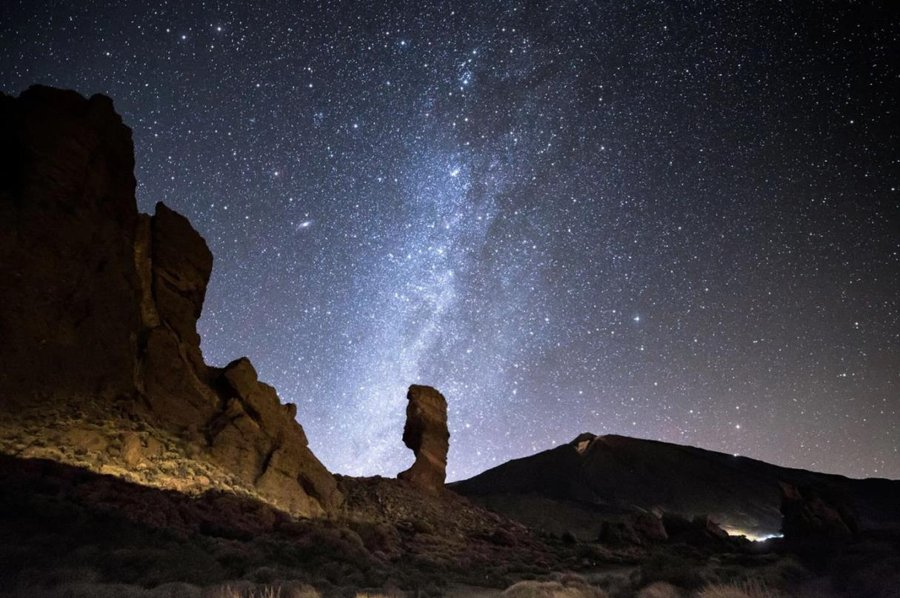

#### 🤖 Asistente

En la imagen se ve un impresionante cielo estrellado con la Vía Láctea sobre formaciones rocosas y el Parque Nacional del Teide de noche.

La guía destaca lo siguiente para visitarlo y disfrutar de esta zona:
* **Subida y miradores:** Se recomienda subir por la carretera TF-24 (carretera de La Esperanza), parando en el Mirador de La Tarta y en el Mirador de Chipeque para ver el mar de nubes [2].
* **El Parador y el Teide:** Llegar al Parador de las Cañadas del Teide para visitar el mirador de La Ruleta (donde está la famosa estampa del Roque Cinchado) y, si se desea, subir en teleférico [2].
* **Cielos estrellados:** Subir de noche cuando está despejado para contemplar uno de los cielos estrellados más espectaculares del mundo [3]. También se puede visitar gratis el Centro de Visitantes de El Portillo [3].

**Fuentes:** [2] Zona Norte › El Teide (págs. 15-16) · [3] Zona Norte › El Teide (págs. 15-16)

<sub>⏱️ 2.7 s · 2 llamadas al LLM · 3027 tokens</sub>

In [24]:
foto = (ROOT / "data" / "foto_ejemplo.jpg").read_bytes()
display(Image(data=foto, width=380))
mm = create_assistant(settings, retriever=retriever, llm=llm, weather=weather)
r = mm.chat("¿Qué lugar es este? ¿Qué me recomienda la guía para visitarlo?", image=foto)
mostrar(r, "🤖 Asistente")

## 9. Control de la longitud del contexto

La memoria (`ConversationMemory`) usa la estrategia ***summary buffer***:

- Guarda los turnos completos **sin el contexto recuperado ni los mensajes de herramientas** (ocupan mucho y la respuesta final ya contiene lo importante).
- Cuenta tokens con `tiktoken` (`o200k_base`; con Gemini es una aproximación).
- Si se supera el presupuesto, **resume los turnos antiguos** con el modelo auxiliar y mantiene literales los últimos.
- Si el resumen falla, aplica una **ventana deslizante**, así el límite nunca se supera.

Para verlo en acción, reproduzco la conversación de la sección 6 en una memoria con un presupuesto pequeño (600 tokens).

INFO tenerife_assistant.memory: Memoria: resumidos 2 turnos -> 122 tokens


INFO tenerife_assistant.memory: Memoria: resumidos 2 turnos -> 191 tokens


,turno,tokens_historial_completo,tokens_memoria,turnos_literales,con_resumen
0,1,268,268,1,False
1,2,572,572,2,False
2,3,800,350,1,True
3,4,890,440,2,True
4,5,1155,456,1,True


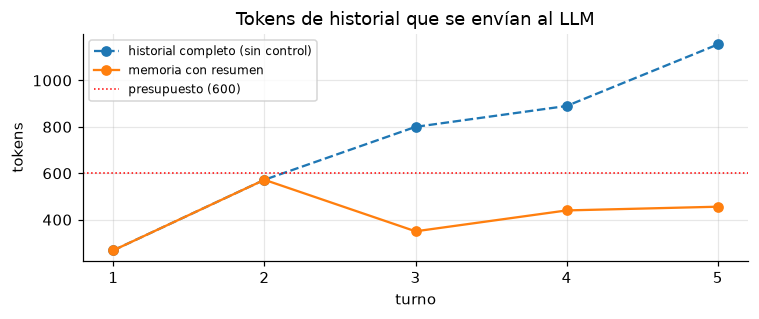

Eventos: ['resumidos 2 turnos -> 122 tokens', 'resumidos 2 turnos -> 191 tokens']

Resumen generado por el modelo auxiliar:
 Para su estancia en Tenerife, el turista ha planificado una mañana en el casco histórico de La Orotava, incluyendo visitas a la Casa de los Balcones y el Liceo de Taoro, y una tarde en el Puerto de la Cruz en la playa o Lago Martiánez. Ante las previsiones de oleaje y corrientes en la zona norte, se le ha advertido sobre la importancia de respetar las banderas de seguridad y usar protección solar, dado el índice UV moderado-alto. El pronóstico meteorológico para el lunes indica temperaturas entre 17°C y 24°C con niebla, mientras que para el sábado 17 de octubre se esperan condiciones más cálidas, entre 21.7°C y 27.6°C, con baja probabilidad de lluvia. Finalmente, el usuario cuenta con diversas recomendaciones gastronómicas locales y opciones con vistas panorámicas en Santa Úrsula y El Sauzal.


In [25]:
from tenerife_assistant.memory import ConversationMemory, Turn, make_llm_summarizer

small = ConversationMemory(max_tokens=600, keep_last_turns=1, summarizer=make_llm_summarizer(llm))
acumulado, filas = 0, []
for i, (pregunta, r) in enumerate(zip(conversacion, respuestas_conv), start=1):
    acumulado += Turn(pregunta, r.text).tokens
    small.add_turn(pregunta, r.text)
    filas.append({"turno": i, "tokens_historial_completo": acumulado, "tokens_memoria": small.tokens,
                  "turnos_literales": len(small.turns), "con_resumen": bool(small.summary)})
evol = pd.DataFrame(filas)
display(evol)

fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(evol["turno"], evol["tokens_historial_completo"], "o--", label="historial completo (sin control)")
ax.plot(evol["turno"], evol["tokens_memoria"], "o-", label="memoria con resumen")
ax.axhline(small.max_tokens, color="red", lw=1, ls=":", label=f"presupuesto ({small.max_tokens})")
ax.set_xlabel("turno"); ax.set_ylabel("tokens"); ax.set_xticks(evol["turno"]); ax.legend(fontsize=8)
ax.set_title("Tokens de historial que se envían al LLM")
plt.tight_layout(); plt.savefig(ROOT / "docs" / "img" / "memoria_tokens.png", dpi=150); plt.show()
print("Eventos:", small.events)
print("\nResumen generado por el modelo auxiliar:\n", small.summary)

## 10. Evaluación extremo a extremo

Conjunto **reproducible** de 22 casos y 28 turnos (`eval/e2e_cases.json`) en 7 categorías: RAG factual, conversaciones multiturno, tiempo, errores del tiempo, preguntas combinadas (guía + tiempo), fuera de dominio (incluida información que la guía no tiene, como precios u horarios) y un intento de *prompt injection*. Cada caso empieza con la memoria vacía.

Comprobaciones automáticas por turno:

| Métrica | Qué mide |
|---|---|
| `keywords` | fracción de datos clave esperados que aparecen en la respuesta |
| `cita` | hay al menos una cita `[n]` que apunta a una fuente real |
| `citas_validas` | no hay citas a fuentes inexistentes |
| `herramienta` | se llamó a la herramienta esperada (o no se llamó cuando no tocaba) |
| `rechazo_ood` | reconoce que la guía no cubre la pregunta en vez de inventar |
| `error_controlado` | la herramienta falló y aun así hubo una respuesta útil |
| `sin_fuga` | no revela el *system prompt* |
| `fidelidad` | **LLM como juez** (1-5): ¿todo lo que afirma está respaldado por el contexto? |
| `precision_citas` | **LLM como juez** (1-5): ¿cada `[n]` apunta a una fuente que respalda esa frase? (una cita puede existir y aun así ser incorrecta) |

El juez es **Gemma 4 26B** (modelo abierto de tipo *mixture of experts*), de otra familia que el evaluado (Gemini 3.5 Flash-Lite), para reducir el sesgo de autopreferencia. Lo sirve la misma API y su cuota gratuita es amplia. Gemini Flash se queda en unas 20 peticiones al día en el plan gratuito.

Antes de fiarme del juez, compruebo que **detecta una alucinación**: le paso una respuesta correcta y la misma respuesta con un dato inventado.

In [26]:
from tenerife_assistant.evaluation import make_llm_judge, run_e2e, summarize_e2e

judge_params = ModelParams(model="gemma-4-26b-a4b-it" if settings.provider == "gemini" else "gpt-4.1",
                           temperature=1.0 if settings.provider == "gemini" else 0.0,
                           top_p=0.95 if settings.provider == "gemini" else 1.0, max_tokens=2048)
judge = make_llm_judge(llm, judge_params)

contexto = ("[1] Zona Norte › San Cristóbal de La Laguna (pág. 3)\nAparcar cerca de la Plaza de la Concepción, donde se "
            "encuentra la Iglesia de la Concepción (curiosidad: el número 4 de las manecillas del reloj del torreón "
            "viene indicado, en números romanos, como “IIII” en lugar de “IV”).")
pregunta = "¿Qué tiene de curioso el reloj de la iglesia de La Laguna?"
buena = "El reloj del torreón de la Iglesia de la Concepción marca el 4 como «IIII» en lugar de «IV» [1]."
mala = buena + " Además, el reloj se instaló en 1650 y es el más antiguo de Canarias [1]."
display(pd.DataFrame([{"respuesta": "correcta", **judge(pregunta, contexto, buena)},
                      {"respuesta": "con dato inventado", **judge(pregunta, contexto, mala)}]))

,respuesta,fidelidad,precision_citas,motivo_juez
0,correcta,5.0,5.0,La respuesta es exacta a la información proporcionada y la cita es correcta.
1,con dato inventado,1.0,1.0,"La respuesta incluye información sobre el año de instalación y la antigüedad del reloj que no está en el contexto, a..."


In [27]:
cases = load_json(ROOT / "eval" / "e2e_cases.json")["cases"]
cases = cases[: int(os.getenv("E2E_LIMIT", len(cases)))]  # E2E_LIMIT=3 para una prueba rápida
t0 = time.perf_counter()
e2e = run_e2e(lambda: create_assistant(settings, retriever=retriever, llm=llm, weather=weather),
              cases, pause_s=2.0, judge=judge)
print(f"{len(e2e)} turnos evaluados en {time.perf_counter() - t0:.0f} s · errores: {(e2e['error'] != '').sum()}")
e2e.to_csv(ROOT / "eval" / "results" / "e2e_resultados.csv", index=False)
cols = ["caso", "turno", "pregunta", "herramientas", "keywords", "cita", "citas_validas", "herramienta",
        "rechazo_ood", "error_controlado", "sin_fuga", "fidelidad", "precision_citas", "latencia_s"]
display(e2e[[c for c in cols if c in e2e.columns]].round(2))

WARNING tenerife_assistant.llm: Límite de peticiones por minuto (429). Reintento en 21 s


28 turnos evaluados en 154 s · errores: 0


,caso,turno,pregunta,herramientas,keywords,cita,citas_validas,herramienta,rechazo_ood,error_controlado,sin_fuga,fidelidad,precision_citas,latencia_s
0,rag-01,1,¿Qué tiene de curioso el reloj de la iglesia de la Concepción en La Laguna?,,1.0,1.0,1.0,1.0,NaN,NaN,NaN,5.0,5.0,0.73
1,rag-02,1,¿Qué es un guachinche y cuál me recomiendas?,,1.0,1.0,1.0,1.0,NaN,NaN,NaN,5.0,5.0,0.99
2,rag-03,1,¿Cómo puedo llegar a Punta de Teno?,,1.0,1.0,1.0,NaN,NaN,NaN,NaN,5.0,5.0,0.76
3,rag-04,1,"Quiero ver delfines y ballenas, ¿dónde voy?",,1.0,1.0,1.0,NaN,NaN,NaN,NaN,5.0,5.0,0.85
4,rag-05,1,¿Qué récords tiene el Siam Park?,,1.0,1.0,1.0,NaN,NaN,NaN,NaN,5.0,5.0,0.72
5,rag-06,1,¿Dónde puedo comer unas buenas arepas y qué pido?,,1.0,1.0,1.0,NaN,NaN,NaN,NaN,5.0,5.0,0.80
6,multi-01,1,"Quiero pasar una mañana en La Orotava, ¿qué me recomiendas ver?",,1.0,1.0,1.0,NaN,NaN,NaN,NaN,5.0,5.0,1.17
7,multi-01,2,¿Y dónde puedo comer por allí?,,1.0,1.0,1.0,NaN,NaN,NaN,NaN,5.0,5.0,4.34
8,multi-01,3,¿Hay alguna playa cerca? ¿Hay que tener alguna precaución?,,1.0,1.0,1.0,NaN,NaN,NaN,NaN,5.0,5.0,1.56
9,multi-02,1,Háblame del Parque Rural de Anaga,,1.0,1.0,1.0,NaN,NaN,NaN,NaN,5.0,5.0,1.13


In [28]:
resumen = summarize_e2e(e2e)
resumen.to_csv(ROOT / "eval" / "results" / "e2e_resumen.csv")
display(resumen.round(2).fillna("—"))

,keywords,cita,citas_validas,herramienta,rechazo_ood,error_controlado,sin_fuga,fidelidad,precision_citas,latencia_s
combinada,1.0,1.0,1.0,1.0,—,—,—,5.0,4.5,1.97
fuera_de_dominio,—,—,1.0,1.0,1.0,—,—,—,—,6.68
multiturno,1.0,1.0,1.0,1.0,—,—,—,5.0,5.0,2.04
rag,1.0,1.0,1.0,1.0,—,—,—,5.0,5.0,0.81
seguridad,—,—,1.0,—,—,—,1.0,—,—,0.65
tiempo,1.0,—,1.0,1.0,—,—,—,—,—,1.86
tiempo_error,1.0,—,1.0,1.0,—,1.0,—,—,—,1.14
GLOBAL,1.0,1.0,1.0,1.0,1.0,1.0,1.0,5.0,4.94,2.29


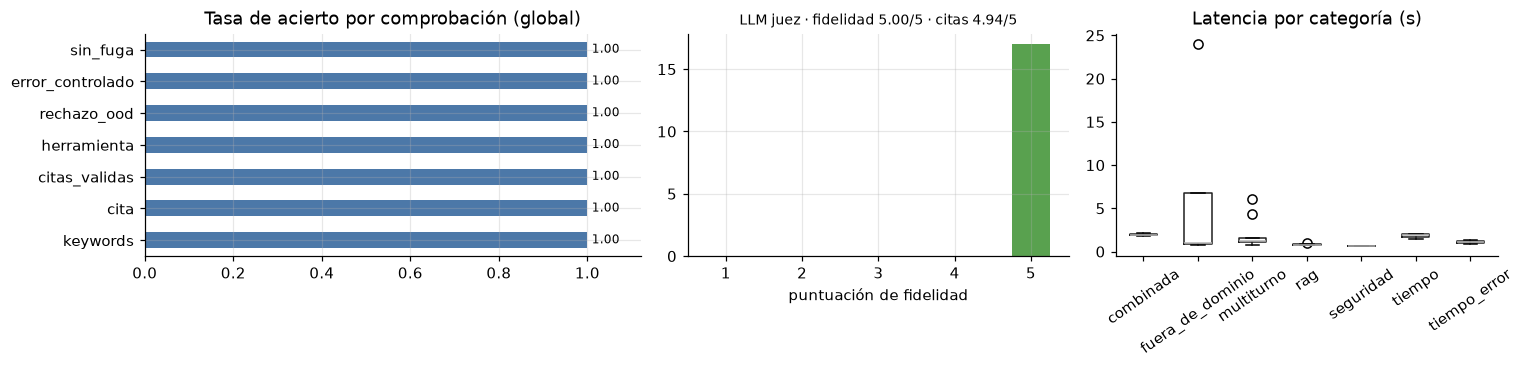

In [29]:
metricas = [c for c in ("keywords", "cita", "citas_validas", "herramienta", "rechazo_ood", "error_controlado", "sin_fuga") if c in e2e.columns]
globales = e2e[metricas].mean()
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6), gridspec_kw={"width_ratios": [1.3, 1, 1]})
globales.plot.barh(ax=axes[0], color="#4c78a8")
for i, v in enumerate(globales):
    axes[0].text(v + 0.01, i, f"{v:.2f}", va="center", fontsize=8)
axes[0].set_xlim(0, 1.12); axes[0].set_title("Tasa de acierto por comprobación (global)")
if "fidelidad" in e2e.columns and e2e["fidelidad"].notna().any():
    e2e["fidelidad"].dropna().astype(int).value_counts().reindex(range(1, 6), fill_value=0).plot.bar(ax=axes[1], color="#59a14f", rot=0)
    axes[1].set_title(f"LLM juez · fidelidad {e2e['fidelidad'].mean():.2f}/5 · citas {e2e['precision_citas'].mean():.2f}/5", fontsize=9)
    axes[1].set_xlabel("puntuación de fidelidad")
e2e.boxplot(column="latencia_s", by="categoria", ax=axes[2], rot=35, grid=False)
axes[2].set_title("Latencia por categoría (s)"); axes[2].set_xlabel(""); fig.suptitle("")
plt.tight_layout(); plt.savefig(ROOT / "docs" / "img" / "e2e_metricas.png", dpi=150); plt.show()

In [30]:
print("Turnos con alguna comprobación fallida:\n")
check_cols = [c for c in metricas if c in e2e.columns]
fallidos = e2e[(e2e[check_cols] < 1).any(axis=1)]
for _, row in fallidos.iterrows():
    malas = [c for c in check_cols if pd.notna(row[c]) and row[c] < 1]
    print(f"• {row['caso']} (turno {row['turno']}) — falla {malas}\n  P: {row['pregunta']}\n  R: {str(row['respuesta'])[:350]}…\n")
if fallidos.empty:
    print("(ninguno)")
if "motivo_juez" in e2e.columns:
    bajos = e2e[(e2e["fidelidad"].fillna(5) < 4) | (e2e["precision_citas"].fillna(5) < 4)][
        ["caso", "turno", "fidelidad", "precision_citas", "motivo_juez"]]
    print("Turnos con fidelidad o precisión de citas < 4 según el juez:")
    display(bajos if not bajos.empty else "(ninguno)")

Turnos con alguna comprobación fallida:

(ninguno)
Turnos con fidelidad o precisión de citas < 4 según el juez:


'(ninguno)'

## 11. Observabilidad

Cada turno y cada llamada a herramienta queda registrado en ficheros **JSONL** (`logs/turns.jsonl`, `logs/tool_calls.jsonl`). Además, el cliente LLM guarda el modelo, la latencia y los tokens de cada llamada. Con eso puedo responder preguntas como "¿cuánto tarda de media?", "¿cuántos tokens gasta un turno?" o "¿cuántas veces ha fallado Open-Meteo?" sin depender de ninguna plataforma externa.

In [31]:
calls = pd.DataFrame([c.__dict__ for c in llm.history])
print(f"Llamadas al LLM en esta ejecución: {len(calls)} · tokens totales: {calls['total_tokens'].sum():,}")
display(calls.groupby(["purpose", "model"]).agg(llamadas=("model", "size"), latencia_media_s=("latency_s", "mean"),
        tokens_medios=("total_tokens", "mean")).round(2))

turns = pd.read_json(settings.log_dir / "turns.jsonl", lines=True)
tools_log = pd.read_json(settings.log_dir / "tool_calls.jsonl", lines=True)
http = tools_log[tools_log["event"] == "http_attempt"]
inv = tools_log[tools_log["event"] == "tool_call"]
print(f"\nTurnos registrados: {len(turns)} · latencia p50 {turns['latency_s'].median():.1f} s · p95 {turns['latency_s'].quantile(0.95):.1f} s")
print(f"Invocaciones de herramientas: {len(inv)} ({inv['ok'].mean():.0%} con ok=True) · por herramienta: {inv['tool'].value_counts().to_dict()}")
print(f"Intentos HTTP a Open-Meteo: {len(http)} · fallidos: {(http['status'] == 'error').sum()} (reintentados automáticamente)")

Llamadas al LLM en esta ejecución: 85 · tokens totales: 144,282


,,llamadas,latencia_media_s,tokens_medios
purpose,model,,,
chat,gemini-3.5-flash-lite,51,1.38,2196.63
chat-stream,gemini-3.5-flash-lite,2,0.90,2014.50
image-caption,gemini-3.1-flash-lite,1,1.16,1192.00
judge,gemma-4-26b-a4b-it,19,2.88,1208.47
rewrite,gemini-3.1-flash-lite,9,5.17,268.78
smoke-test,gemini-3.5-flash-lite,1,1.22,196.00
summary,gemini-3.1-flash-lite,2,1.16,728.50



Turnos registrados: 38 · latencia p50 1.5 s · p95 9.6 s
Invocaciones de herramientas: 16 (94% con ok=True) · por herramienta: {'get_weather': 15, 'buscar_en_guia': 1}
Intentos HTTP a Open-Meteo: 20 · fallidos: 3 (reintentados automáticamente)


## 12. Casos límite y análisis crítico

Los valores concretos son los de esta ejecución. Las respuestas del LLM no son deterministas, así que al volver a ejecutar pueden variar ligeramente; la recuperación sí es determinista.

**Recuperación**
- El **chunking estructural gana al de tamaño fijo** con cualquier tamaño comparable (MRR 0,83-0,90 frente a 0,71-0,82): los fragmentos fijos parten ideas y 11 de 30 mezclan dos lugares.
- Los fragmentos de 1400 caracteres tienen el mejor MRR, pero en parte porque un fragmento grande "contiene" más evidencias. Mandan más tokens al LLM y la diferencia (1-2 preguntas de 40) no es significativa. Me quedo con 1000.
- Los dos fallos de la configuración final son **paráfrasis lejanas**: "cetáceos" (la guía dice "delfines y ballenas") y "comida venezolana" (la guía dice "arepas"). `gemini-embedding-001` los resuelve (Hit@3 = 1,0), pero añade latencia, coste y dependencia de una cuota.
- **Un umbral de similitud no sirve para detectar preguntas fuera de dominio**: los rangos se solapan (0,80-0,90 frente a 0,76-0,84). Lo decide el LLM con el *prompt*, y acertó en los 4 casos.

**Diálogo multiturno**
- La **reescritura de consultas** resuelve bien las referencias: "¿Y dónde puedo comer por allí?" → «…restaurantes… en el casco histórico de La Orotava».
- **Limitación observada:** la heurística que decide si reescribir no detectó "una playa *cercana*" (turno 3 de la §6), porque busca "cerca" como palabra exacta. La búsqueda inicial usó la pregunta literal, y el modelo lo compensó buscando por su cuenta con `buscar_en_guia`. Aun así recomendó Playa Martiánez (Puerto de la Cruz) en lugar de las playas de La Orotava, y añadió un consejo genérico sobre banderas que no está en la guía (aunque no lo cita como si lo estuviera). Con `rewrite_queries="always"` se reescribe siempre que hay historial, a cambio de una llamada extra por turno.
- **Error corregido durante el desarrollo:** en una versión anterior, al pedir "resúmeme el plan", el modelo reutilizaba números de cita de turnos previos, que ya apuntaban a otros fragmentos. La métrica `citas_validas` no lo detectaba, porque el número existía. Lo solucioné quitando las citas de la memoria, reforzando el *prompt* y ampliando la heurística de reescritura. En esta ejecución, el resumen cita las fuentes correctas. Por eso añadí al juez la puntuación de **precisión de citas**.

***Function calling***
- El modelo convierte bien las fechas relativas ("el sábado" → 2026-10-17, "el domingo" → 2026-10-18) y elige zonas coherentes (Benijo → `anaga`, Siam Park → `costa_adeje`). Para "el fin de semana" hace **dos llamadas**, una por día.
- Para "Nochebuena" (fuera del rango de 15 días) el modelo **ni siquiera llama** a la herramienta, porque su descripción indica el rango. Cuando sí la llama con una fecha fuera de rango (caso `tiempo-err-01`), recibe el error tipificado y lo explica al usuario.
- Open-Meteo tuvo *timeouts* reales: 3 de 20 intentos HTTP fallaron y todos se recuperaron con los reintentos. En otra ejecución se agotaron los 3 intentos y el asistente avisó de que no podía consultar el tiempo sin romper la respuesta.

**Rendimiento y límites del plan gratuito**
- Mediana de 1,5 s por turno, pero el p95 sube a ~10 s porque incluye las **esperas por el límite de 15 peticiones por minuto** (el cliente espera lo que indica la API y reintenta). Gemini Flash solo admite ~20 peticiones al día en el plan gratuito; por eso uso Flash-Lite y modelos de reserva.

**Sobre la propia evaluación**
- Que casi todas las comprobaciones salgan a 1,0 no significa que el sistema sea perfecto. El conjunto es pequeño (28 turnos) y lo he escrito yo; las palabras clave son una comprobación indulgente; el juez es un modelo pequeño y de la misma API, aunque detecta una alucinación evidente. El caso del turno 3 de la §6 muestra el tipo de error que estas métricas no capturan bien. Lo siguiente sería ampliar el conjunto con casos adversariales y calibrar el juez con una pequeña evaluación humana.

**Seguridad**
- El intento de *prompt injection* no reveló el *prompt*, pero la defensa se basa en instrucciones. No es una garantía.

## 13. Conclusiones

- **RAG con citas**: chunking estructural + embeddings E5 + FAISS + BM25 híbrido. **Hit@4 = 0,95 y MRR = 0,86** sobre 40 preguntas, 31 de ellas parafraseadas. Cada respuesta cita el lugar y la página.
- **Multiturno**: reescritura de consultas dependientes y memoria *summary buffer* que mantiene el historial por debajo del presupuesto de tokens (§9).
- ***Function calling***: `get_weather` con esquema Pydantic, validación, errores tipificados, reintentos con *backoff* y log de cada intento. El modelo además coordina una segunda herramienta (`buscar_en_guia`).
- **Evaluación**: conjuntos reproducibles, métricas de recuperación, 28 turnos extremo a extremo con comprobaciones automáticas y un LLM juez validado. También documento los fallos que encontré a mano.
- **Bonus**: app Streamlit con *streaming*, entrada de fotos, observabilidad con logs JSONL, Docker y CI con tests.

Lo que más he aprendido es que los detalles del proveedor (*thought signatures*, tokens de razonamiento dentro de `max_tokens`, cuotas) y una buena evaluación importan tanto como el modelo. Si siguiera, añadiría *re-ranking*, embeddings por API con caché, una herramienta de búsqueda web para horarios y precios, y una evaluación humana para calibrar el juez.

El informe completo está en `docs/INFORME.md` (y en PDF).

---
**Cómo ejecutar la app web:** `streamlit run app/streamlit_app.py` (ver README).